# 03 缺失值处理方案比较
对应任务：**比较缺失值处理方案，编写可复用的预处理代码**
方案不能靠"感觉哪个高级就用哪个"，得用同一套验证口径量出来。
本 notebook 用 **按组切分的 5 折交叉验证**（`StratifiedGroupKFold`，理由见 notebook 02）
在**同一份数据、同一套特征**上比较 5 种方案，两个模型各跑一遍。
> 这里出现的模型**只是评估缺失方案的尺子**，不是最终提交模型。
> 建模是另一位成员的任务。



In [1]:
import os
import sys
import time
from pathlib import Path

START = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next(p for p in [START, *START.parents]
            if (p / "src" / "preprocess.py").is_file())
sys.path.insert(0, str(ROOT))
from src.paths import EXPERIMENTS_DIR, FIGURES_DIR
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")   # 沙箱里 joblib 探测核数会失败
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplcache"))

FIG = FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from src import preprocess as pp

matplotlib.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
matplotlib.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Microsoft YaHei")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

print("pandas", pd.__version__)



pandas 3.0.5


In [2]:
train_raw, test_raw = pp.load_raw()
train, test = pp.build_features_combined(train_raw, test_raw)
print("train:", train.shape, "| test:", test.shape)
print("原始缺失单元格数(train):", int(train_raw.isna().sum().sum()))



train: (8693, 41) | test: (4277, 40)
原始缺失单元格数(train): 2324


## 3.1 五个方案
| 代号 | 方案 | 具体做法 | 预期 |
|---|---|---|---|
| S0 | **不填充** | 保留 NaN，交给原生支持缺失的 `HistGradientBoosting` | 省事基准，树模型常够用 |
| S1 | **删行** | 丢掉任何含缺失的行 | 丢 24% 样本，信息损失大 |
| S2 | **简单填充** | 数值取中位数、分类取众数 | 常见做法 |
| S3 | **简单填充+指示位** | S2 基础上为每个原本有缺失的列加 `<列>_na` | 实际收益需验证 |
| S4 | **规则+组内填充** | 领域规则 + 同组信息 + 兜底统计量（`Preprocessor("rule_group")`） | 预期最好 |
S4 用到的三条依据都是 notebook 01 里**实测确认**的：
1. 消费>0 ⇒ 非冷冻睡眠 → 可确定性地补 119 个 `CryoSleep`
2. `HomePlanet`、`Cabin.Side` 组内恒定 → 同组信息可以补
3. `Destination`、`Deck`、`CabinNum` 组内可不同 → 只能退到统计量



In [3]:
rows = [
    ("S0 不填充", "保留 NaN", "只适用于能处理缺失的模型（树模型）"),
    ("S1 删行", "丢弃任何含缺失的行", "train 8693 -> 6606，丢 24.0%"),
    ("S2 简单填充", "中位数 / 众数", "不看字段语义，一视同仁"),
    ("S3 简单填充+指示位", "S2 + 每列缺失标志位", "检验缺失本身是否携带信息"),
    ("S4 规则+组内填充", "领域规则 + 同组 + 统计量兜底", "推荐方案"),
]
pd.DataFrame(rows, columns=["代号", "做法", "备注"])



,代号,做法,备注
0,S0 不填充,保留 NaN,只适用于能处理缺失的模型（树模型）
1,S1 删行,丢弃任何含缺失的行,train 8693 -> 6606，丢 24.0%
2,S2 简单填充,中位数 / 众数,不看字段语义，一视同仁
3,S3 简单填充+指示位,S2 + 每列缺失标志位,检验缺失本身是否携带信息
4,S4 规则+组内填充,领域规则 + 同组 + 统计量兜底,推荐方案


## 3.2 评估框架
- 切分：`StratifiedGroupKFold(5)`，按 `gggg` 组切，保证同组不跨折（notebook 02 证明必须这么做）。
- 模型：`HistGradientBoostingClassifier`（固定 random_state=0）
  与 `LogisticRegression`（标准化后）。两种模型对填充方案的敏感度不同，都看。
- 指标：Accuracy（与比赛一致），报告 5 折的均值 ± 标准差。
- 使用相同的基础特征与折；S3 额外加入真正进入模型的原始字段缺失标记。
- 姓氏计数统一使用公开 train+test 的无标签特征池；每折填补器只拟合训练折。




In [4]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

FOLDS = pp.group_folds(train, n_splits=5, seed=42)
y_all = train[pp.TARGET].astype(int).values


STRATEGY_KEYS = {
    "S0 不填充": None, "S1 删行": "drop", "S2 简单填充": "simple",
    "S3 简单填充+指示位": "indicator", "S4 规则+组内填充": "rule_group",
}


def run_cv(strategy, model_name, use_rules=True):
    accs, t0 = [], time.time()
    for tr_idx, va_idx in FOLDS:
        Xtr, ytr, Xva, yva = pp.prepare_fold_matrices(
            train, tr_idx, va_idx, STRATEGY_KEYS[strategy], use_rules)
        if STRATEGY_KEYS[strategy] == "indicator":
            indicators = [c for c in Xtr if c.endswith("_na")]
            assert indicators, "S3 缺失标记未进入建模矩阵"
            assert not any("Transported" in c for c in Xtr), "标签进入了特征"

        if model_name == "HistGB":
            model = HistGradientBoostingClassifier(random_state=0, max_iter=300,
                                                   learning_rate=0.06,
                                                   l2_regularization=1.0)
        else:
            Xtr = Xtr.fillna(0.0)
            Xva = Xva.fillna(0.0)
            model = make_pipeline(StandardScaler(),
                                  LogisticRegression(max_iter=3000, C=1.0))
        with joblib.parallel_backend("sequential"):
            model.fit(Xtr, ytr)
        accs.append(float(model.score(Xva, yva)))
    return np.array(accs), time.time() - t0


STRATEGIES = ["S0 不填充", "S2 简单填充", "S3 简单填充+指示位", "S4 规则+组内填充"]
MODELS = {"HistGB": ["S0 不填充", "S2 简单填充", "S3 简单填充+指示位", "S4 规则+组内填充"],
          "LogisticRegression": ["S2 简单填充", "S3 简单填充+指示位", "S4 规则+组内填充"]}



跑 5 折 × (4+3) 组，下面会打印耗时。为了结果可复现，
这里固定了所有随机种子（折的划分 seed=42，模型 random_state=0）。



In [5]:
results = {}
detail = []
for model_name, strategies in MODELS.items():
    for s in strategies:
        accs, secs = run_cv(s, model_name)
        results[(s, model_name)] = accs
        detail.append({"方案": s, "模型": model_name,
                       "准确率均值": round(accs.mean(), 4),
                       "标准差": round(accs.std(ddof=1), 4),
                       "折数": len(accs), "耗时秒": round(secs, 1)})
        print(f"{s:22s} {model_name:20s} acc={accs.mean():.4f} ± {accs.std(ddof=1):.4f}"
              f"  ({secs:.1f}s)")

main_tbl = pd.DataFrame(detail)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)
main_tbl.to_csv(EXPERIMENTS_DIR / "missing_strategy_comparison.csv",
                index=False, encoding="utf-8-sig")



S0 不填充                 HistGB               acc=0.8031 ± 0.0064  (4.9s)


S2 简单填充                HistGB               acc=0.8058 ± 0.0079  (4.4s)


S3 简单填充+指示位            HistGB               acc=0.8063 ± 0.0095  (5.2s)


S4 规则+组内填充             HistGB               acc=0.8050 ± 0.0093  (10.1s)


S2 简单填充                LogisticRegression   acc=0.7943 ± 0.0031  (0.4s)


S3 简单填充+指示位            LogisticRegression   acc=0.7944 ± 0.0049  (0.4s)


S4 规则+组内填充             LogisticRegression   acc=0.7943 ± 0.0051  (6.1s)


准确率均值（按组切分 5 折）：
模型           HistGB  LogisticRegression
方案                                     
S0 不填充       0.8031                 NaN
S2 简单填充      0.8058              0.7943
S3 简单填充+指示位  0.8063              0.7944
S4 规则+组内填充   0.8050              0.7943


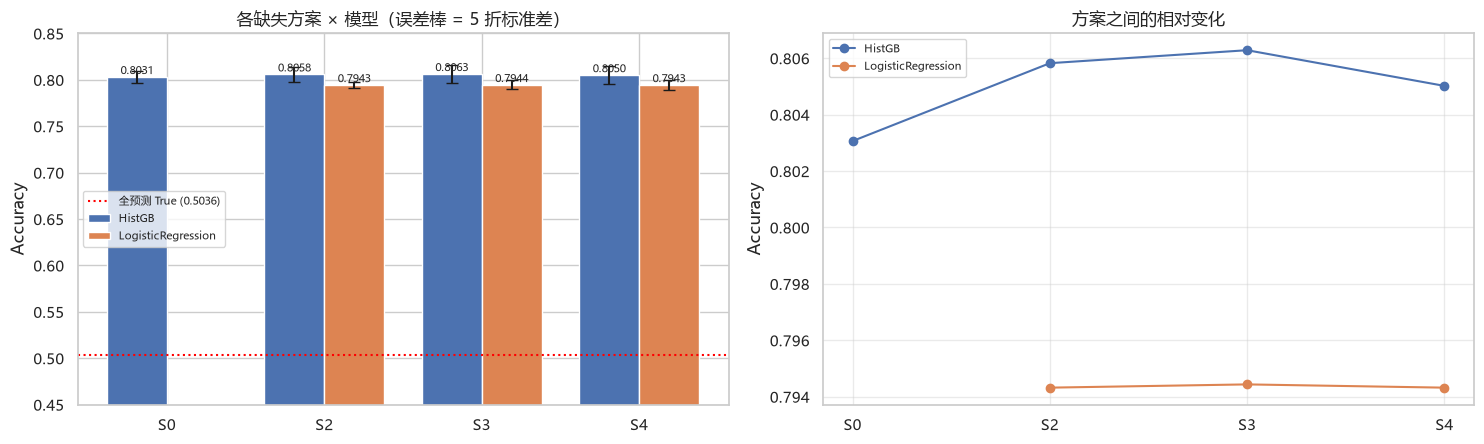

In [6]:
pivot = main_tbl.pivot(index="方案", columns="模型", values="准确率均值")
pivot = pivot.reindex([s for s in STRATEGIES if s in pivot.index])
print("准确率均值（按组切分 5 折）：")
print(pivot.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
x = np.arange(len(pivot.index))
w = 0.38
for i, m in enumerate(pivot.columns):
    xs, vals, errs = [], [], []
    for j, s in enumerate(pivot.index):
        if (s, m) not in results:      # 例如 S0 在逻辑回归下不存在
            continue
        xs.append(x[j] + (i - 0.5) * w)
        vals.append(results[(s, m)].mean())
        errs.append(results[(s, m)].std(ddof=1))
    axes[0].bar(xs, vals, width=w, yerr=errs, capsize=4, label=m)
    for xi, v in zip(xs, vals):
        axes[0].text(xi, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
axes[0].axhline(0.5036, ls=":", color="red", label="全预测 True (0.5036)")
axes[0].set_xticks(x, [s.split(" ", 1)[0] for s in pivot.index])
axes[0].set_ylim(0.45, 0.85)
axes[0].set_ylabel("Accuracy")
axes[0].set_title("各缺失方案 × 模型（误差棒 = 5 折标准差）")
axes[0].legend(fontsize=8)

for i, m in enumerate(pivot.columns):
    s_list = [s for s in pivot.index if not np.isnan(pivot.loc[s, m])]
    axes[1].plot([s.split(" ", 1)[0] for s in s_list],
                 [results[(s, m)].mean() for s in s_list], "o-", label=m)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("方案之间的相对变化")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.4)
plt.tight_layout()
fig.savefig(FIG / "03_missing_strategy_comparison.png", dpi=140, bbox_inches="tight")
plt.show()



## 3.3 方案 S1（删行）单独评估
删行**不能**放进上面的主表：训练集与验证集都被限制在"完整行"上，
评估口径和其他方案不同，直接比会误导。这里单列出来，同时把样本损失标清楚。



In [7]:
accs, secs = run_cv("S1 删行", "HistGB")
complete_mask = ~train_raw.isna().any(axis=1).values
drop_tbl = pd.DataFrame([{
    "方案": "S1 删行 (HistGB)",
    "准确率均值": round(accs.mean(), 4),
    "标准差": round(accs.std(ddof=1), 4),
    "训练样本数": int(complete_mask.sum()),
    "丢掉样本数": int((~complete_mask).sum()),
    "丢弃比例%": round((~complete_mask).mean() * 100, 2),
    "评估口径": "训练/验证都只用完整行，与其他方案不可直接比较",
}])
print(drop_tbl.to_string(index=False))
drop_tbl.to_csv(EXPERIMENTS_DIR / "complete_case_comparison.csv",
                index=False, encoding="utf-8-sig")
print(f"\n(S1 耗时 {secs:.1f}s)")



[drop] 6954 -> 5285 行（丢弃 1669，24.0%）
[drop] 1739 -> 1321 行（丢弃 418，24.0%）


[drop] 6954 -> 5285 行（丢弃 1669，24.0%）
[drop] 1739 -> 1321 行（丢弃 418，24.0%）


[drop] 6954 -> 5271 行（丢弃 1683，24.2%）
[drop] 1739 -> 1335 行（丢弃 404，23.2%）


[drop] 6955 -> 5297 行（丢弃 1658，23.8%）
[drop] 1738 -> 1309 行（丢弃 429，24.7%）


[drop] 6955 -> 5286 行（丢弃 1669，24.0%）
[drop] 1738 -> 1320 行（丢弃 418，24.1%）


            方案  准确率均值    标准差  训练样本数  丢掉样本数  丢弃比例%                    评估口径
S1 删行 (HistGB) 0.8049 0.0126   6606   2087  24.01 训练/验证都只用完整行，与其他方案不可直接比较

(S1 耗时 3.6s)


## 3.4 消融：领域规则本身值多少？
S4 里有两条东西：**领域规则**（消费>0 ⇒ 非冷冻）和**组内信息**。
把规则关掉再跑一遍同组填充，就能量出规则单独的贡献。
这是"清洗决策值不值得做"的直接证据。



In [8]:
abl = []
for label, use_rules in [("S4 完整（规则+组内）", True), ("S4 去掉领域规则（只用组内）", False)]:
    for m in ["HistGB", "LogisticRegression"]:
        a, secs = run_cv("S4 规则+组内填充", m, use_rules=use_rules)
        abl.append({"配置": label, "模型": m, "准确率均值": round(a.mean(), 4),
                    "标准差": round(a.std(ddof=1), 4)})
abl_tbl = pd.DataFrame(abl)
print(abl_tbl.to_string(index=False))
abl_tbl.to_csv(EXPERIMENTS_DIR / "domain_rule_ablation.csv",
               index=False, encoding="utf-8-sig")

piv = abl_tbl.pivot(index="配置", columns="模型", values="准确率均值")
print("\n规则带来的差值（百分点）：")
print(((piv.loc["S4 完整（规则+组内）"] - piv.loc["S4 去掉领域规则（只用组内）"]) * 100)
      .round(3).to_string())



             配置                 模型  准确率均值    标准差
   S4 完整（规则+组内）             HistGB 0.8050 0.0093
   S4 完整（规则+组内） LogisticRegression 0.7943 0.0051
S4 去掉领域规则（只用组内）             HistGB 0.8014 0.0093
S4 去掉领域规则（只用组内） LogisticRegression 0.7933 0.0051

规则带来的差值（百分点）：
模型
HistGB                0.36
LogisticRegression    0.10


## 3.5 修正后的结论与建模交接
旧版本的缺失标记被模型列白名单丢弃，原“S3 零收益”结论撤回。
本次 S3 使用最多 12 个原始字段缺失标记，且每折断言它们确实进入模型。
列间缺失相关很弱，仅说明未发现明显共同缺失结构，不能证明完全随机缺失。
S4 仅对 HomePlanet/Side 使用一致的组级分类值，Destination/Deck 使用训练折众数。
Age、消费、VIP、CryoSleep 的组内统计填补仍是候选启发式方法，效果由实验判断。
新分数由上方运行输出生成，并保存到 reports/experiments/，不再硬编码旧分数。
S1 只在完整样本子集评估，不与其他方案直接排名。
姓氏人数在公开 train+test 特征池统一计算，不使用测试标签。
这是批次特征可见的验证设定；填补器、标准化器和模型仍需每折独立拟合。



In [9]:
print("本次有效对照结果：")
print(main_tbl[["方案", "模型", "准确率均值", "标准差"]].to_string(index=False))
for m in MODELS:
    d = main_tbl[main_tbl["模型"] == m].set_index("方案")
    delta = (d.loc["S3 简单填充+指示位", "准确率均值"] -
             d.loc["S2 简单填充", "准确率均值"]) * 100
    print(f"{m}：S3 相对 S2 变化 {delta:+.2f} 个百分点；仅为当前五折观察，不是显著性检验。")



本次有效对照结果：
         方案                 模型  准确率均值    标准差
     S0 不填充             HistGB 0.8031 0.0064
    S2 简单填充             HistGB 0.8058 0.0079
S3 简单填充+指示位             HistGB 0.8063 0.0095
 S4 规则+组内填充             HistGB 0.8050 0.0093
    S2 简单填充 LogisticRegression 0.7943 0.0031
S3 简单填充+指示位 LogisticRegression 0.7944 0.0049
 S4 规则+组内填充 LogisticRegression 0.7943 0.0051
HistGB：S3 相对 S2 变化 +0.05 个百分点；仅为当前五折观察，不是显著性检验。
LogisticRegression：S3 相对 S2 变化 +0.01 个百分点；仅为当前五折观察，不是显著性检验。


## 3.6 建模成员使用方式
```python
import pandas as pd
from src import preprocess as pp
raw, raw_test = pp.load_raw()
features, test_features = pp.build_features_combined(raw, raw_test)
fold_map = pd.read_csv("features/folds.csv", dtype={"PassengerId": str})
fold_of = features.PassengerId.map(fold_map.set_index("PassengerId")["fold"])
assert fold_of.notna().all()
for fold in range(1, 6):
    tr_idx = (fold_of != fold).to_numpy().nonzero()[0]
    va_idx = (fold_of == fold).to_numpy().nonzero()[0]
    Xtr, ytr, Xva, yva = pp.prepare_fold_matrices(features, tr_idx, va_idx)
    # 在 Xtr/ytr 上拟合；使用 Xva/yva 验证，标准化也只在训练折拟合。
```
最终确定方案后，才可在全部训练数据上 fit 填补器和模型，预测完整测试集。
features/train_clean.csv 是这种全量处理的产物，不能作为逐折拟合的替代品。
